# Ujian Tengah Semester Deteksi dan Pengenalan Obyek

Nama : Muhamad Naufal Zaky\
NIM : 26928023

Link repository : 

# 1. Persiapan Data

## 1.1 Pemilihan Objek

Analisis ini membandingkan Artificial Neural Network (ANN) dan Convolutional Neural Network (CNN) dalam klasifikasi gambar buah. Kelas yang digunakan adalah Banana, Watermelon, dan Salak ($K=3$). Variabel respons $Y$ berupa kelas buah, sedangkan prediktor $X$ berupa nilai piksel RGB.

Sumber data: [Fruits-360 100×100](https://github.com/fruits-360/fruits-360-100x100) (Mureșan dan Oltean, 2018).

TensorFlow digunakan untuk pemodelan, Pillow untuk preprocessing, dan scikit-learn untuk pembagian data serta evaluasi. Seed ditetapkan sebesar 2026. Setiap metode diuji tanpa augmentasi (baseline) dan dengan augmentasi (augmented).

In [1]:
import os
import logging

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
logging.getLogger('tensorflow').setLevel(logging.ERROR)

from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import json

from PIL import Image, ImageOps, ImageDraw
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from IPython.display import display

tf.get_logger().setLevel('ERROR')
seed = 2026
keras.utils.set_random_seed(seed)

classes = ['Banana', 'Watermelon', 'Salak']
n_classes = len(classes)
class_map = {f'{k} 1': k for k in classes}
external_map = {k: k for k in classes}
image_size = (100, 100)
batch_size = 32
max_epochs = 80
patience = 4
lr = 0.001
dropout_rate = 0.2
val_ratio = 0.2
scenarios = {'baseline': False, 'augmented': True}

root_dir = Path(r'C:\Users\HP 845 G9\fruits-360')
if not (root_dir / 'fruits-360' / 'Training').is_dir() and (Path.cwd() / 'fruits-360' / 'Training').is_dir():
    root_dir = Path.cwd()
data_dir = root_dir / 'fruits-360'
external_dir = root_dir / 'New-Fruits'
additional_dir = root_dir / 'Additional-Fruits'
output_dir = root_dir / 'output_ann_cnn'
table_dir = output_dir / 'tables'
figure_dir = output_dir / 'figures'
model_dir = output_dir / 'models'
log_dir = output_dir / 'logs'
image_ext = {'.jpg', '.jpeg', '.png', '.bmp'}

for p in [table_dir, figure_dir, model_dir, log_dir]:
    p.mkdir(parents=True, exist_ok=True)

def save_table(df, name, index=False):
    df.to_csv(table_dir / f'{name}.csv', index=index)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figure_dir / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def relative_path(p):
    return Path(p).relative_to(root_dir.resolve()).as_posix()

## 1.2 Pengumpulan Data dan Analisis Deskriptif

Data utama berasal dari folder `Banana 1`, `Watermelon 1`, dan `Salak 1`. Jumlah gambar masing-masing kelas adalah 656, 632, dan 652, sehingga diperoleh 1.940 gambar. Proporsi kelas dihitung melalui $p_k=n_k/\sum_{j=1}^K n_j$.

Fruits-360 memiliki variasi sudut pengambilan, tetapi pencahayaan relatif terkontrol dan latar belakang putih. Tidak terdapat gambar pada sumber tambahan (`Additional images: 0`). Variasi pencahayaan dan latar pada training diperluas melalui augmentasi. Sebanyak 60 gambar dari `New-Fruits` digunakan secara terpisah untuk pengujian eksternal.

In [2]:
def read_split(path, mapping, source):
    folders = [p for p in path.iterdir() if p.is_dir()]
    rows = []
    for name, k in sorted(mapping.items()):
        key = name.lower().replace('-', ' ')
        matches = [p for p in folders if p.name.lower().replace('-', ' ') == key]
        if len(matches) != 1:
            raise ValueError(f'{path / name}: n_folders = {len(matches)}')
        paths = sorted(p for p in matches[0].rglob('*')
                       if p.is_file() and p.suffix.lower() in image_ext)
        if not paths:
            raise ValueError(f'n = 0: {matches[0]}')
        rows.extend((str(p.resolve()), k, classes.index(k), source) for p in paths)
    return pd.DataFrame(rows, columns=['path', 'class', 'y', 'source'])

training = read_split(data_dir / 'Training', class_map, 'fruits360')
test = read_split(data_dir / 'Test', class_map, 'fruits360')
external = read_split(external_dir, external_map, 'external')

if additional_dir.is_dir():
    additional = read_split(additional_dir, external_map, 'additional')
    if (additional['class'].value_counts().reindex(classes, fill_value=0) < 10).any():
        raise ValueError('Additional-Fruits: n_k < 10')
    add_train, add_test = train_test_split(additional, test_size=0.2,
                                           stratify=additional['y'], random_state=seed)
    training = pd.concat([training, add_train], ignore_index=True)
    test = pd.concat([test, add_test], ignore_index=True)

df = pd.concat([training, test, external], ignore_index=True)
if df['path'].duplicated().any():
    raise ValueError('Duplicate image paths')

freq = pd.DataFrame({'training': training['class'].value_counts(),
                     'test': test['class'].value_counts(),
                     'external': external['class'].value_counts()}).reindex(classes)
if (freq[['training', 'test']].sum(axis=1) < 10).any():
    raise ValueError('n_k < 10')
freq['total_main'] = freq['training'] + freq['test']
freq['proportion'] = freq['total_main'] / freq['total_main'].sum()
print('Additional images:', int((df['source'] == 'additional').sum()))

Additional images: 0


## 1.3 Preprocessing dan Pembagian Data

Resizing mempertahankan rasio aspek dengan skala $s=\min(100/h,100/w)$. Normalisasi $x'_{ijc}=x_{ijc}/255$ menghasilkan $X\in[0,1]^{100\times100\times3}$ sebelum augmentasi.

Sebanyak 1.455 gambar pada folder Training dibagi menjadi 80% training dan 20% validation. Seluruh 485 gambar pada folder Test digunakan untuk testing. Data eksternal tidak digunakan dalam estimasi maupun seleksi model.

Augmentasi data training dilakukan melalui flip, rotasi, zoom, translasi, penyesuaian kontras dan kecerahan, serta penggantian latar menggunakan latar sintetis. Misalkan $M$ adalah mask piksel latar putih yang terhubung ke tepi gambar dan $B$ adalah citra latar sintetis, maka

$$\widetilde X=(1-M)\odot X+M\odot B.$$

Penggantian latar dilakukan dengan probabilitas 0,5 pada gambar training Fruits-360. Latar asli validation, testing, dan eksternal dipertahankan. Bobot kelas dihitung dari frekuensi training:

$$w_k=\frac{n_{\rm train}}{K n_k}.$$

In [3]:
train, val = train_test_split(training, test_size=val_ratio,
                              stratify=training['source'] + '_' + training['class'],
                              random_state=seed)
splits = {'train': train, 'validation': val, 'test': test, 'external': external}
n_k = np.bincount(train['y'].to_numpy(), minlength=n_classes)
w = len(train) / (n_classes * n_k)
class_weight = dict(enumerate(w.astype(float)))

counts = pd.DataFrame({k: v['class'].value_counts() for k, v in splits.items()}).reindex(classes)
counts['total_main'] = freq['total_main']
counts['proportion'] = freq['proportion']
counts['weight'] = w
save_table(counts, 'data_summary', index=True)
display(counts.round(4))

n_total = len(training) + len(test)
print(f'Training folder / Test: {len(training)/n_total:.2%} / {len(test)/n_total:.2%}')
print(f'Train / Validation / Test: {len(train)/n_total:.2%} / {len(val)/n_total:.2%} / {len(test)/n_total:.2%}')

manifest = pd.concat([v.assign(split=k) for k, v in splits.items()], ignore_index=True)
manifest['path'] = manifest['path'].map(relative_path)
save_table(manifest, 'data_split')

,train,validation,test,external,total_main,proportion,weight
class,,,,,,,
Banana,392,98,166,20,656,0.3381,0.9898
Watermelon,380,95,157,20,632,0.3258,1.0211
Salak,392,98,162,20,652,0.3361,0.9898


Training folder / Test: 75.00% / 25.00%
Train / Validation / Test: 60.00% / 15.00% / 25.00%


**Hasil pembagian data.** Data dibagi menjadi tiga bagian, yaitu training sebanyak 1.164 gambar (60%), validation sebanyak 291 gambar (15%), dan testing sebanyak 485 gambar (25%). Proporsi kelas Banana, Watermelon, dan Salak pada data utama masing-masing sebesar 33,81%, 32,58%, dan 33,61%. Bobot kelas berturut-turut sebesar 0,9898, 1,0211, dan 0,9898, yang menunjukkan bahwa distribusi kelas relatif seimbang.

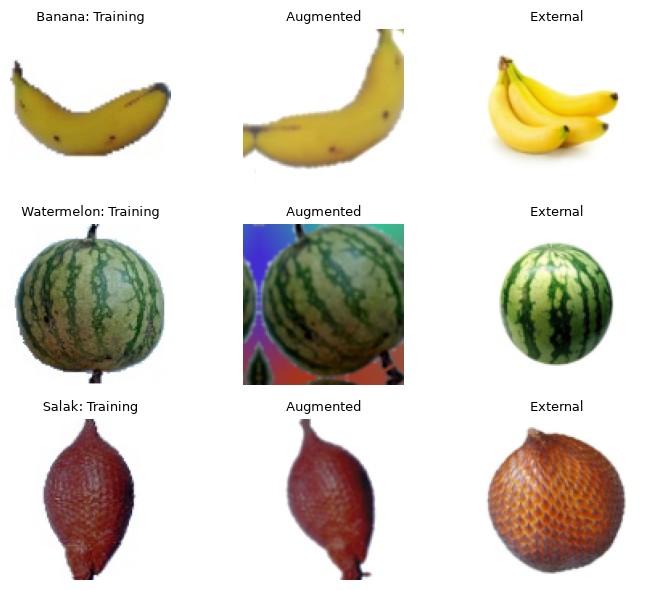

In [4]:
def read_rgb(p):
    with Image.open(p) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

def read_image(p):
    im = read_rgb(p)
    im = ImageOps.pad(im, image_size[::-1], method=Image.Resampling.BILINEAR,
                      color=(255, 255, 255))
    return np.asarray(im)

def load_images(df):
    return np.stack([read_image(p) for p in df['path']])

def background_mask(x):
    white = np.min(x, axis=2) >= 240
    z = np.pad(white.astype(np.uint8) * 255, 1, constant_values=255)
    im = Image.fromarray(z).copy()
    ImageDraw.floodfill(im, (0, 0), 128)
    return (np.asarray(im)[1:-1, 1:-1] == 128)[..., None]

x_train = load_images(train)
x_val = load_images(val)
x_test = load_images(test)
x_external = load_images(external)
mask_train = np.stack([background_mask(x) if s == 'fruits360'
                       else np.zeros((*image_size, 1), dtype=bool)
                       for x, s in zip(x_train, train['source'])])

def normalize(x):
    return tf.cast(x, tf.float32) / 255.0

def augment_background(x, mask):
    n = tf.shape(x)[0]
    b = tf.image.resize(tf.random.uniform((n, 2, 2, 3), 0.15, 0.95), image_size)
    use = tf.random.uniform((n, 1, 1, 1)) < 0.5
    return tf.where(tf.logical_and(mask, use), b, x)

def make_dataset(x, y, shuffle=False, mask=None):
    y = np.asarray(y)
    data = (x, y) if mask is None else (x, y, mask)
    ds = tf.data.Dataset.from_tensor_slices(data)
    if shuffle:
        ds = ds.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    if mask is None:
        ds = ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(lambda x, y, mask: (augment_background(normalize(x), mask), y))
    return ds.prefetch(tf.data.AUTOTUNE)

ds_val = make_dataset(x_val, val['y'])
ds_test = make_dataset(x_test, test['y'])
ds_external = make_dataset(x_external, external['y'])

def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.15, fill_mode='reflect'),
        layers.RandomZoom(0.15, fill_mode='reflect'),
        layers.RandomTranslation(0.1, 0.1, fill_mode='reflect'),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.15, value_range=(0, 1))
    ], name='augmentation')

n_cols = 4 if additional_dir.is_dir() else 3
fig, ax = plt.subplots(n_classes, n_cols, figsize=(2.5*n_cols, 2*n_classes))
aug = build_augmentation()
for i, k in enumerate(classes):
    j = np.flatnonzero((train['class'].to_numpy() == k) & (train['source'].to_numpy() == 'fruits360'))[0]
    l = np.flatnonzero(external['class'].to_numpy() == k)[0]
    z = augment_background(normalize(x_train[j:j+1]), mask_train[j:j+1])
    z = aug(z, training=True)[0]
    images = [x_train[j], tf.clip_by_value(z, 0, 1).numpy(), x_external[l]]
    titles = [f'{k}: Training', 'Augmented', 'External']
    if additional_dir.is_dir():
        p = additional.loc[additional['class'] == k, 'path'].iloc[0]
        images.insert(2, read_image(p))
        titles.insert(2, 'Additional')
    for a, x, title in zip(ax[i], images, titles):
        a.imshow(x)
        a.set_title(title, fontsize=9)
        a.axis('off')
save_figure(fig, 'sample_images')

# 2. Artificial Neural Network (ANN)

## 2.1 Implementasi ANN

Citra RGB diubah menjadi vektor $\boldsymbol\in\mathbb R^30000$. Hidden layer menggunakan fungsi aktivasi ReLU, $h=\max(0,W\boldsymbol+b)$, kemudian dilanjutkan dengan Batch Normalization dan dropout sebesar 0,2. Batch Normalization digunakan untuk menstandarkan nilai aktivasi dalam setiap batch.

$$\widetilde h=\gamma\frac{h-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}+\beta.$$

Probabilitas kelas diperoleh dari softmax. Bobot model diestimasi dengan meminimumkan sparse categorical cross-entropy berbobot:

$$\widehat p_k=\frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}},\qquad L_B=-\frac{1}{|B|}\sum_{i\in B}w_{y_i}\log\widehat p_{i,y_i}.$$

Pada tahap evaluasi, augmentasi data dan dropout dinonaktifkan, sedangkan Batch Normalization menggunakan statistik bergerak (moving statistics) yang diperoleh selama proses training.

In [5]:
def compile_model(m):
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def build_ann(units, augment=False):
    m = keras.Sequential([keras.Input(shape=(*image_size, 3))])
    if augment:
        m.add(build_augmentation())
    m.add(layers.Flatten())
    for h in units:
        m.add(layers.Dense(h, activation='relu', kernel_initializer='he_normal'))
        m.add(layers.BatchNormalization())
        m.add(layers.Dropout(dropout_rate))
    m.add(layers.Dense(n_classes, activation='softmax', kernel_initializer='glorot_uniform'))
    return compile_model(m)

ann_specs = {'ann_1': (64,), 'ann_2': (128, 64)}

## 2.2 Arsitektur, Pelatihan, dan Evaluasi ANN

| Komponen | ANN-1 | ANN-2 |
|---|---:|---:|
| Input (flatten) | 30.000 | 30.000 |
| Hidden layer | 1 | 2 |
| Neuron hidden | 64 | 128, 64 |
| Neuron output | 3 | 3 |

Hidden layer menggunakan ReLU dan inisialisasi He normal (varians $2/n_{\rm in}$). Output menggunakan softmax dan Glorot uniform pada $[-a,a]$,  $a=\sqrt{6/(n_{\rm in}+n_{\rm out})}$. Estimasi bobot menggunakan backpropagation dan Adam ($\eta=0.001$).

Pelatihan dibatasi 80 epoch dan dihentikan jika validation loss tidak mencapai minimum baru selama 4 epoch berturut-turut. Rasio folder Training dan Test adalah 75:25 dengan rasio training, validation, dan testing aktual adalah 60:15:25. Loss validasi tidak menggunakan bobot kelas.

Untuk confusion matrix $C$, akurasi dan jumlah kesalahan dihitung sebagai

$$\mathrm{Acc}=\frac{\operatorname{tr}(C)}{\sum_{ij}C_{ij}},\qquad n_{\rm error}=\sum_{ij}C_{ij}-\operatorname{tr}(C).$$

Macro F1 dihitung sebagai $K^{-1}\sum_{k=1}^K F_{1,k}$, dengan $F_{1,k}=2P_kR_k/(P_k+R_k)$.

In [6]:
models, tuning, histories, metrics, reports, predictions, cmats = {}, {}, [], {}, [], [], {}

def fit_candidates(build, specs, name, augment):
    rows = []
    best_score = (np.inf, np.inf)
    model_file = model_dir / f'{name}.keras'
    for candidate, spec in specs.items():
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        m = build(spec, augment)
        stop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min',
                                             patience=patience, restore_best_weights=True)
        ds = make_dataset(x_train, train['y'], shuffle=True,
                          mask=mask_train if augment else None)
        print(f'\n{name}/{candidate}')
        t0 = perf_counter()
        hist = m.fit(ds, validation_data=ds_val, epochs=max_epochs,
                     class_weight=class_weight, callbacks=[stop], shuffle=False, verbose=2)
        elapsed = perf_counter() - t0
        h = pd.DataFrame(hist.history)
        h.insert(0, 'epoch', np.arange(1, len(h)+1))
        h.insert(0, 'candidate', candidate)
        h.insert(0, 'model', name)
        histories.append(h)
        if not np.isfinite(h['val_loss']).all():
            raise ValueError(f'Non-finite validation loss: {name}/{candidate}')
        j = h['val_loss'].idxmin()
        loss = h.loc[j, 'val_loss']
        acc = h.loc[j, 'val_accuracy']
        score = (loss, -acc)
        rows.append([name, candidate, j+1, len(h), loss, acc, m.count_params(), elapsed])
        print(f'{name}/{candidate}: epoch {j+1}/{len(h)}, val_loss = {loss:.6g}')
        if score < best_score:
            best_score = score
            m.save(model_file)
    res = pd.DataFrame(rows, columns=['model', 'candidate', 'best_epoch', 'epochs_run',
                                      'val_loss', 'val_accuracy', 'parameters', 'train_time_s'])
    res = res.sort_values(['val_loss', 'val_accuracy'], ascending=[True, False],
                           kind='stable').reset_index(drop=True)
    res['selected'] = res.index == 0
    tuning[name] = res
    return keras.models.load_model(model_file, compile=False)

def evaluate(m, name, ds, df, split):
    prob = m.predict(ds, verbose=0)
    y = df['y'].to_numpy()
    y_hat = prob.argmax(axis=1)
    cmat = confusion_matrix(y, y_hat, labels=range(n_classes))
    cmats[name, split] = cmat
    acc = np.trace(cmat) / cmat.sum()
    f1 = f1_score(y, y_hat, labels=range(n_classes), average='macro', zero_division=0)
    metrics[name, split] = {'accuracy': acc, 'macro_f1': f1,
                            'n_error': int(cmat.sum() - np.trace(cmat))}
    report = classification_report(y, y_hat, labels=range(n_classes), target_names=classes,
                                   output_dict=True, zero_division=0)
    r = pd.DataFrame(report).T.drop(index='accuracy').rename_axis('class').reset_index()
    reports.append(r.assign(model=name, split=split))
    pred = pd.DataFrame(prob, columns=[f'p_{k.lower()}' for k in classes])
    pred.insert(0, 'predicted', np.array(classes)[y_hat])
    pred.insert(0, 'actual', df['class'].to_numpy())
    pred.insert(0, 'path', df['path'].map(relative_path).to_numpy())
    pred.insert(0, 'split', split)
    pred.insert(0, 'model', name)
    pred['p_max'] = prob.max(axis=1)
    predictions.append(pred)
    return pred

for scenario, augment in scenarios.items():
    name = f'ann_{scenario}'
    models[name] = fit_candidates(build_ann, ann_specs, name, augment)
    evaluate(models[name], name, ds_test, test, 'test')

display(pd.DataFrame({k: v for (k, s), v in metrics.items() if s == 'test'}).T.round(4))


ann_baseline/ann_1
Epoch 1/80
37/37 - 2s - 52ms/step - accuracy: 0.9124 - loss: 0.2808 - val_accuracy: 0.6151 - val_loss: 1.3175
Epoch 2/80
37/37 - 1s - 20ms/step - accuracy: 0.9820 - loss: 0.0919 - val_accuracy: 0.8935 - val_loss: 0.1947
Epoch 3/80
37/37 - 1s - 19ms/step - accuracy: 0.9948 - loss: 0.0492 - val_accuracy: 0.9691 - val_loss: 0.0839
Epoch 4/80
37/37 - 1s - 20ms/step - accuracy: 0.9966 - loss: 0.0283 - val_accuracy: 0.9897 - val_loss: 0.0338
Epoch 5/80
37/37 - 1s - 18ms/step - accuracy: 0.9991 - loss: 0.0222 - val_accuracy: 1.0000 - val_loss: 0.0378
Epoch 6/80
37/37 - 1s - 19ms/step - accuracy: 0.9983 - loss: 0.0170 - val_accuracy: 1.0000 - val_loss: 0.0116
Epoch 7/80
37/37 - 1s - 19ms/step - accuracy: 1.0000 - loss: 0.0134 - val_accuracy: 1.0000 - val_loss: 0.0080
Epoch 8/80
37/37 - 1s - 19ms/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 1.0000 - val_loss: 0.0044
Epoch 9/80
37/37 - 1s - 19ms/step - accuracy: 1.0000 - loss: 0.0087 - val_accuracy: 1.0000 - val_los

,accuracy,macro_f1,n_error
ann_baseline,1.0000,1.0000,0.0
ann_augmented,0.9876,0.9878,6.0


**Hasil testing ANN.** Model baseline berhasil mengklasifikasikan seluruh 485 gambar secara tepat dengan akurasi 100%. Sementara itu, model augmented memperoleh 479 prediksi benar dari 485 gambar, dengan akurasi 98,76% dan macro F1 sebesar 0,9878. Sebanyak enam gambar Banana mengalami kesalahan klasifikasi dan diprediksi sebagai Salak.

## 2.3 Prediksi Gambar Baru dengan ANN

Pengujian menggunakan 60 gambar baru yang terdiri atas 20 gambar untuk setiap kelas. Label aktual ditentukan berdasarkan nama folder pada `New-Fruits`, sedangkan kelas hasil prediksi ditetapkan berdasarkan nilai probabilitas softmax tertinggi.

$$\widehat y_i=\arg\max_k\widehat p_{ik},\qquad \mathrm{Acc}_{\rm ext}=\frac{1}{60}\sum_{i=1}^{60}\mathbf 1(y_i=\widehat y_i).$$

Gambar ditampilkan bersama label aktual, kelas prediksi, dan probabilitas maksimum. Prediksi salah ditandai dengan warna merah.

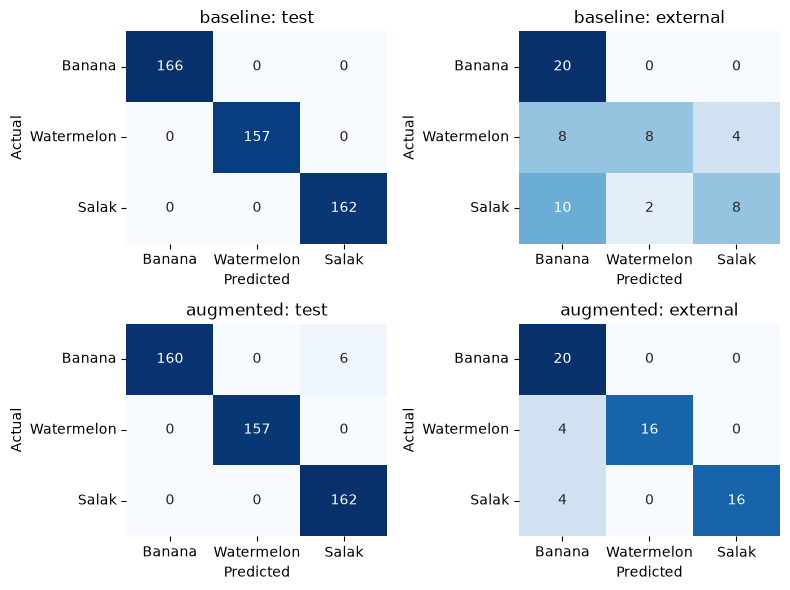

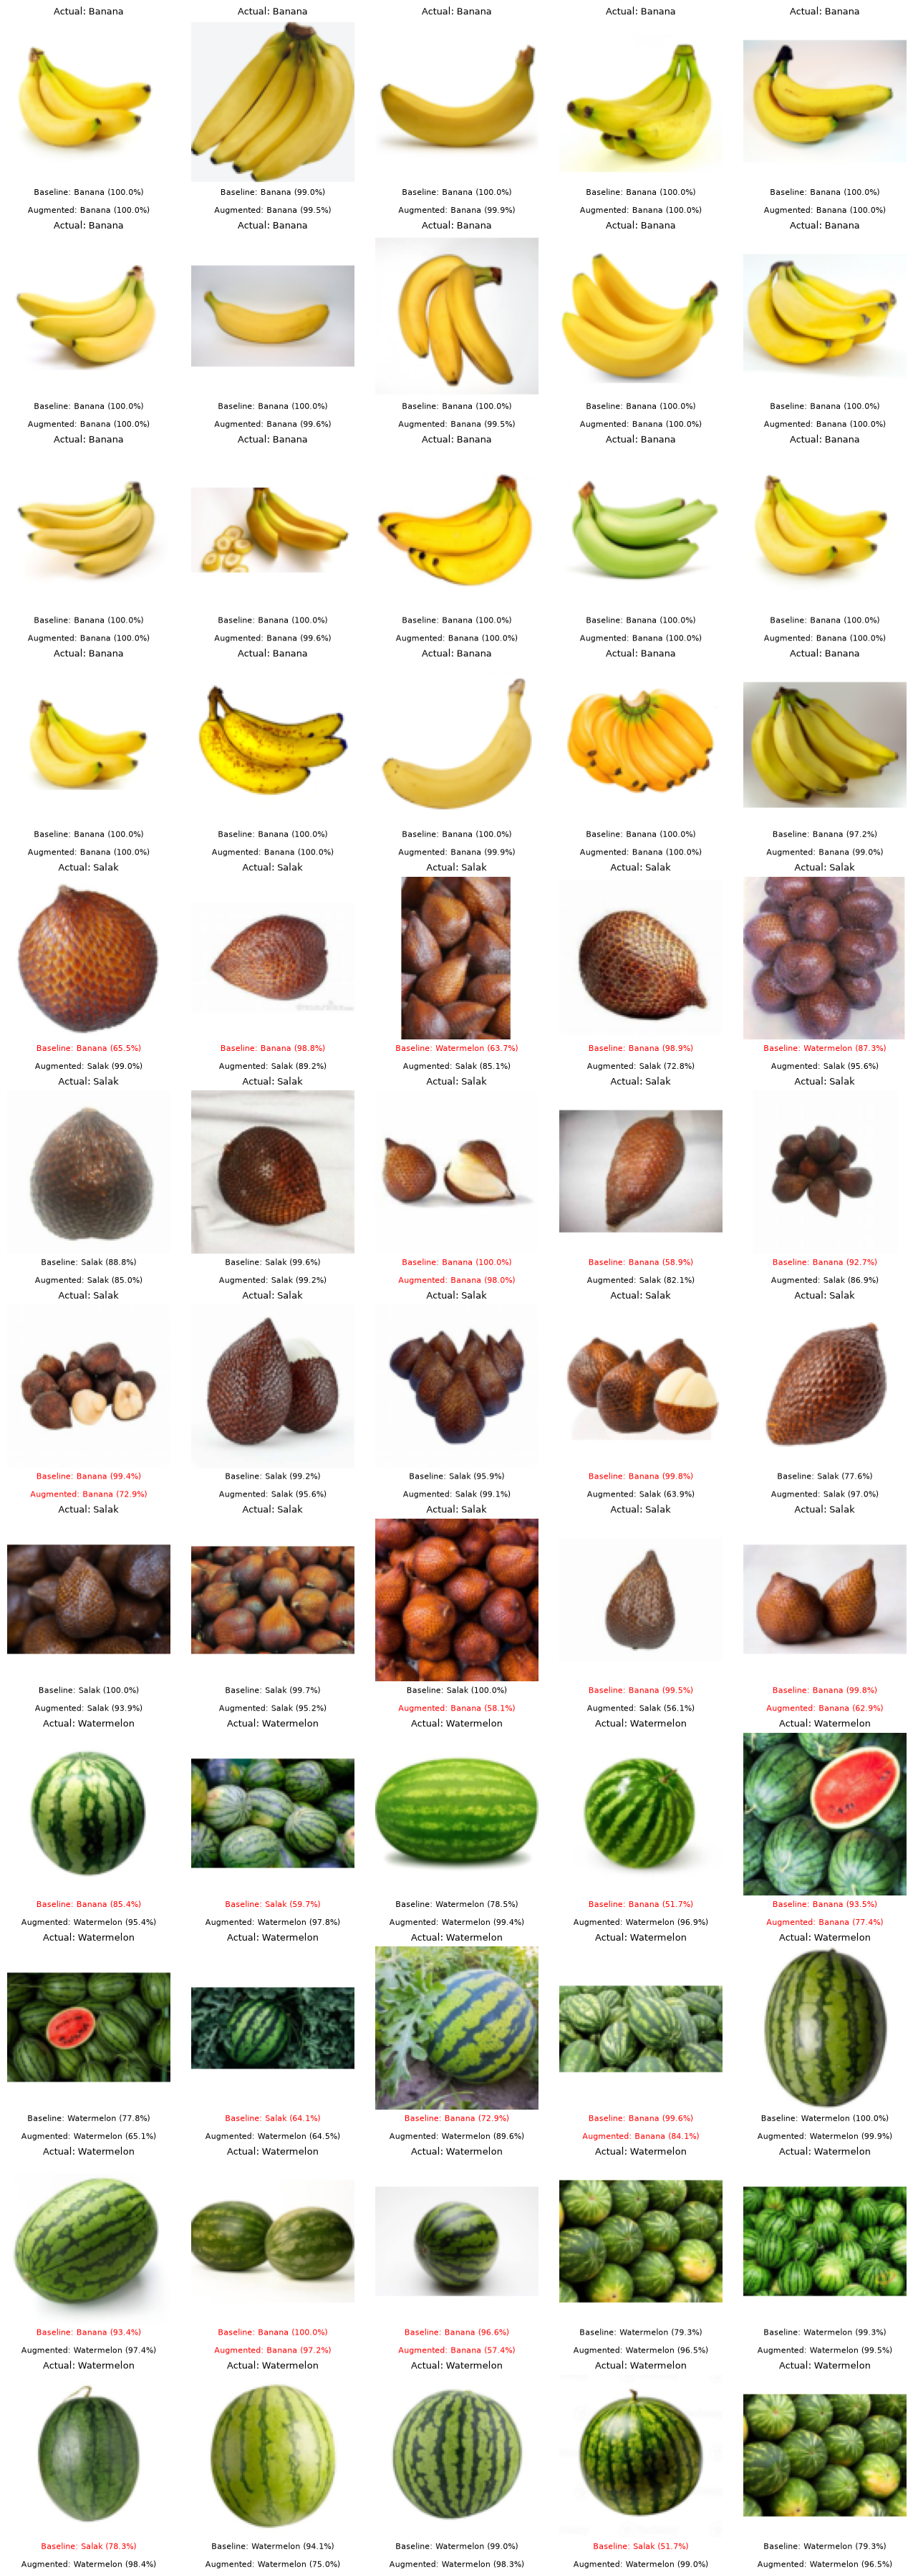

,model,path,actual,predicted,p_max
0,ann_baseline,New-Fruits/Banana/Image_1.jpg,Banana,Banana,1.0000
1,ann_baseline,New-Fruits/Salak/Image_1.jpg,Salak,Banana,0.6555
2,ann_baseline,New-Fruits/Watermelon/Image_1.jpg,Watermelon,Banana,0.8543
3,ann_augmented,New-Fruits/Banana/Image_1.jpg,Banana,Banana,1.0000
4,ann_augmented,New-Fruits/Salak/Image_1.jpg,Salak,Salak,0.9903
5,ann_augmented,New-Fruits/Watermelon/Image_1.jpg,Watermelon,Watermelon,0.9539


,accuracy,macro_f1,n_error
ann_baseline,0.6000,0.5743,24.0
ann_augmented,0.8667,0.8704,8.0


In [7]:
def plot_external(family, pred):
    n = len(external)
    n_cols = 5
    n_rows = (n + n_cols - 1) // n_cols
    fig, ax = plt.subplots(n_rows, n_cols, figsize=(13, 3*n_rows), squeeze=False)
    for a in ax.flat:
        a.axis('off')
    for i, a in enumerate(ax.flat[:n]):
        actual = external['class'].iloc[i]
        a.imshow(x_external[i])
        a.set_title(f'Actual: {actual}', fontsize=9)
        for j, scenario in enumerate(scenarios):
            row = pred[scenario].iloc[i]
            color = 'black' if row['predicted'] == actual else 'red'
            a.text(0.5, -0.03 - 0.11*j,
                   f"{scenario.capitalize()}: {row['predicted']} ({row['p_max']:.1%})",
                   transform=a.transAxes, ha='center', va='top', color=color, fontsize=8)
    save_figure(fig, f'external_prediction_{family}')

def external_results(family):
    fig, ax = plt.subplots(2, 2, figsize=(8, 6))
    rows = []
    pred_ext = {}
    for i, scenario in enumerate(scenarios):
        name = f'{family}_{scenario}'
        pred = evaluate(models[name], name, ds_external, external, 'external')
        pred_ext[scenario] = pred
        rows.append(pred.groupby('actual', sort=False).head(1))
        for j, split in enumerate(['test', 'external']):
            sns.heatmap(cmats[name, split], annot=True, fmt='d', cmap='Blues', cbar=False,
                        xticklabels=classes, yticklabels=classes, ax=ax[i, j])
            ax[i, j].set(title=f'{scenario}: {split}', xlabel='Predicted', ylabel='Actual')
    save_figure(fig, f'confusion_matrix_{family}')
    plot_external(family, pred_ext)
    display(pd.concat(rows, ignore_index=True)[['model', 'path', 'actual', 'predicted', 'p_max']].round(4))
    display(pd.DataFrame({k: v for (k, s), v in metrics.items()
                          if k.startswith(family) and s == 'external'}).T.round(4))

external_results('ann')

**Hasil eksternal ANN.** Pada pengujian terhadap 60 gambar baru, model baseline menghasilkan 36 klasifikasi benar dengan akurasi 60,00%, sedangkan model augmented memperoleh 52 klasifikasi benar dengan akurasi 86,67%. Sejalan dengan hal tersebut, nilai macro F1 juga meningkat dari 0,5743 menjadi 0,8704.

## 2.4 Tuning dan Analisis ANN

Seleksi arsitektur dan epoch didasarkan pada $\min_{c,t}L_{\rm val}(c,t)$. Jika loss antarkandidat sama, dipilih akurasi validasi tertinggi. Data testing dan eksternal tidak digunakan untuk seleksi. Kurva dan tabel berikut menunjukkan riwayat seluruh kandidat.

,model,candidate,best_epoch,epochs_run,val_loss,val_accuracy,parameters,train_time_s,selected
0,ann_baseline,ann_2,18,22,0.000054,1.0000,3849347,29.77,True
1,ann_baseline,ann_1,14,18,0.001081,1.0000,1920515,13.87,False
2,ann_augmented,ann_2,5,9,0.019681,0.9931,3849347,19.18,True
3,ann_augmented,ann_1,4,8,0.023368,0.9931,1920515,12.25,False


ann_baseline/ann_2 | Best epoch: 18


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.943299,0.173387,0.632302,5.239459
2,0.987972,0.039554,0.680412,0.899036
3,0.998282,0.016415,0.989691,0.037520
4,1.000000,0.009000,1.000000,0.005851
5,0.999141,0.007113,1.000000,0.001797
6,0.999141,0.005380,1.000000,0.001305
7,1.000000,0.004309,1.000000,0.000523
8,0.999141,0.003669,1.000000,0.000906
9,1.000000,0.002801,1.000000,0.000221


ann_baseline/ann_1 | Best epoch: 14


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.912371,0.280795,0.615120,1.317484
2,0.981959,0.091917,0.893471,0.194740
3,0.994845,0.049167,0.969072,0.083938
4,0.996564,0.028332,0.989691,0.033796
5,0.999141,0.022197,1.000000,0.037837
6,0.998282,0.017003,1.000000,0.011623
7,1.000000,0.013435,1.000000,0.008032
8,1.000000,0.009033,1.000000,0.004445
9,1.000000,0.008724,1.000000,0.005614


ann_augmented/ann_2 | Best epoch: 5


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.759450,0.598491,0.505155,2.269427
2,0.873711,0.338948,0.903780,0.212855
3,0.926117,0.226049,0.982818,0.079934
4,0.926117,0.204935,0.993127,0.040464
5,0.923540,0.193733,0.993127,0.019681
6,0.940722,0.164984,0.975945,0.062738
7,0.943299,0.144445,0.958763,0.091731
8,0.933849,0.171667,0.776632,0.456836
9,0.957045,0.134324,0.986254,0.032721


ann_augmented/ann_1 | Best epoch: 4


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.829038,0.454651,0.917526,0.263060
2,0.899485,0.294031,0.975945,0.084597
3,0.932131,0.224926,0.993127,0.038814
4,0.932131,0.199919,0.993127,0.023368
5,0.931271,0.193322,0.969072,0.098892
6,0.951031,0.174453,0.910653,0.199270
7,0.945876,0.161524,1.000000,0.039808
8,0.939863,0.162940,0.920962,0.199081


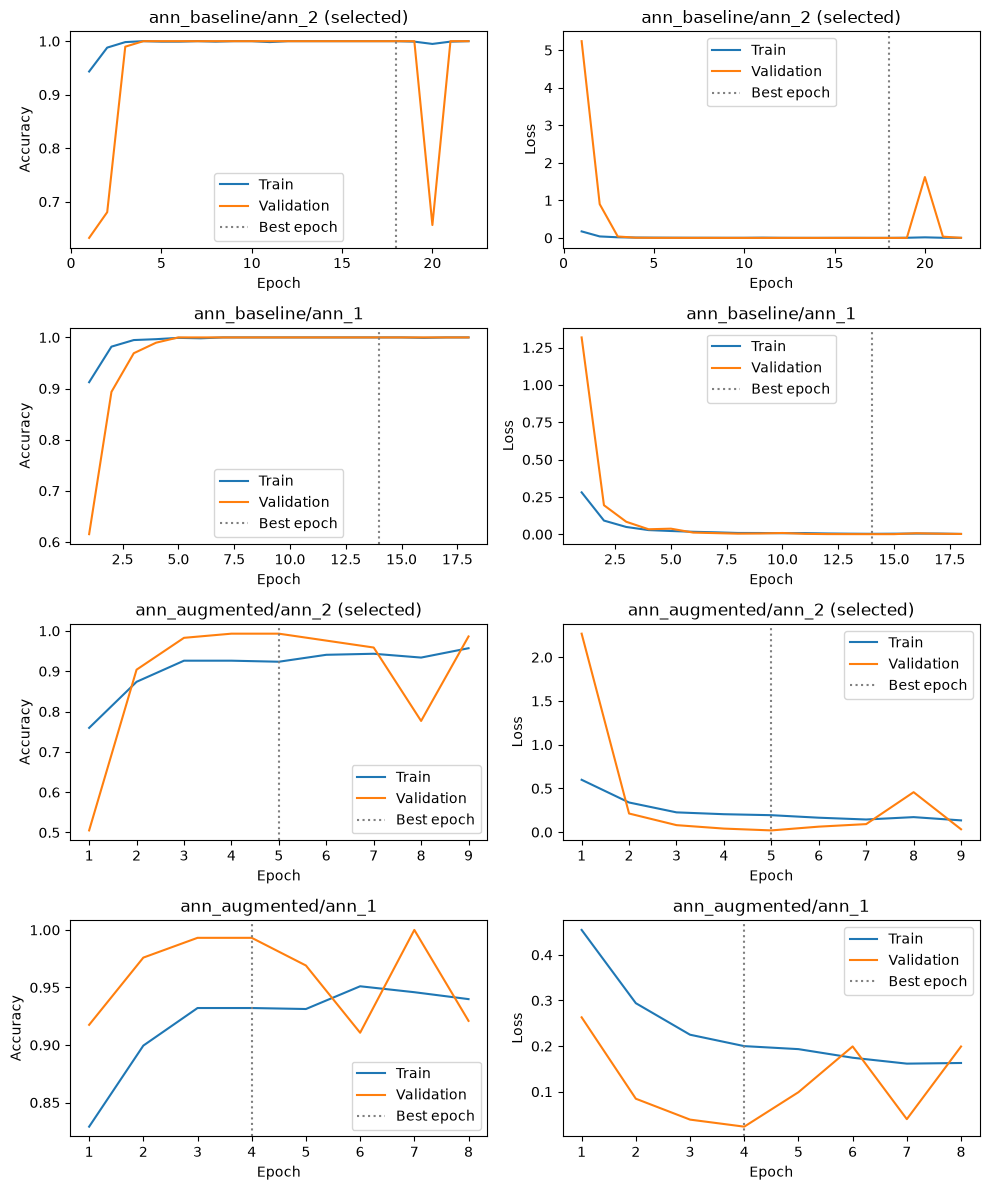

ANN: selisih akurasi eksternal akibat augmentasi = +26.67 pp


In [8]:
def tuning_results(family):
    res = pd.concat([tuning[f'{family}_{s}'] for s in scenarios], ignore_index=True)
    display(res.round({'val_accuracy': 4, 'train_time_s': 2}))
    fig, ax = plt.subplots(len(res), 2, figsize=(10, 3 * len(res)), squeeze=False)
    for i, r in res.iterrows():
        name, candidate = r['model'], r['candidate']
        h = next(h for h in histories if h['model'].iat[0] == name and h['candidate'].iat[0] == candidate)
        print(f'{name}/{candidate} | Best epoch: {r["best_epoch"]}')
        with pd.option_context('display.max_rows', None):
            display(h[['epoch', 'accuracy', 'loss', 'val_accuracy', 'val_loss']].round(6).set_index('epoch'))
        label = f'{name}/{candidate}' + (' (selected)' if r['selected'] else '')
        for j, metric in enumerate(['accuracy', 'loss']):
            ax[i, j].plot(h['epoch'], h[metric], label='Train')
            ax[i, j].plot(h['epoch'], h[f'val_{metric}'], label='Validation')
            ax[i, j].axvline(r['best_epoch'], linestyle=':', color='gray', label='Best epoch')
            ax[i, j].set(title=label, xlabel='Epoch', ylabel=metric.capitalize())
            ax[i, j].legend()
    save_figure(fig, f'learning_curve_{family}')

tuning_results('ann')
a = metrics['ann_baseline', 'external']['accuracy']
b = metrics['ann_augmented', 'external']['accuracy']
print(f'ANN: selisih akurasi eksternal akibat augmentasi = {100*(b-a):+.2f} pp')

**Hasil tuning ANN.** ANN-2 menjadi model terpilih pada kedua skenario pengujian. Pada skenario baseline, nilai validation loss terendah sebesar $5.40426\times10^-5$ diperoleh pada epoch ke-18 dari total 22 epoch, dengan akurasi 100%. Pada skenario augmented, nilai minimum validation loss sebesar 0,019681 dicapai pada epoch ke-5 dari total 9 epoch, dengan akurasi 99,31%. Pada kedua skenario, ANN-2 menghasilkan nilai validation loss yang lebih rendah dibandingkan ANN-1.

Penerapan augmentasi meningkatkan akurasi pengujian eksternal sebesar 26,67 poin persentase, meskipun akurasi testing mengalami penurunan sebesar 1,24 poin persentase. Temuan ini menunjukkan bahwa akurasi testing yang tinggi tidak selalu mencerminkan kemampuan generalisasi model yang baik terhadap data baru.

# 3. Convolutional Neural Network (CNN)

## 3.1 Implementasi CNN

CNN melakukan ekstraksi fitur lokal menggunakan filter berukuran $3\times3$ melalui operasi konvolusi.

$$z_{ijk}=b_k+\sum_{u=-1}^{1}\sum_{v=-1}^{1}\sum_c w_{uvck}x_{i+u,j+v,c}.$$

Setiap lapisan konvolusi dilanjutkan dengan fungsi aktivasi ReLU, Batch Normalization, dan max pooling. Selanjutnya, Global Average Pooling (GAP) digunakan untuk merangkum nilai pada setiap feature map menjadi satu nilai representatif.

$$g_k=\frac{1}{HW}\sum_{i=1}^H\sum_{j=1}^W a_{ijk}.$$

Penggunaan GAP bertujuan untuk menyederhanakan dimensi fitur sebelum memasuki dense layer tanpa menambah jumlah parameter model.

In [9]:
def build_cnn(filters, augment=False):
    m = keras.Sequential([keras.Input(shape=(*image_size, 3))])
    if augment:
        m.add(build_augmentation())
    for f in filters:
        m.add(layers.Conv2D(f, (3, 3), padding='same', activation='relu',
                            kernel_initializer='he_normal'))
        m.add(layers.BatchNormalization())
        m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal'))
    m.add(layers.BatchNormalization())
    m.add(layers.Dropout(dropout_rate))
    m.add(layers.Dense(n_classes, activation='softmax', kernel_initializer='glorot_uniform'))
    return compile_model(m)

cnn_specs = {'cnn_1': (16, 32, 64), 'cnn_2': (32, 32, 64)}

## 3.2 Arsitektur, Pelatihan, dan Evaluasi CNN

| Komponen | CNN-1 | CNN-2 |
|---|---|---|
| Input | 100×100×3 | 100×100×3 |
| Filter Conv 1–3 | 16, 32, 64 | 32, 32, 64 |
| Ukuran filter | 3×3 | 3×3 |
| Max pooling | 2×2, stride 2 | 2×2, stride 2 |
| GAP | 64 fitur | 64 fitur |
| Fully connected layer | 2 (64, 3 neuron) | 2 (64, 3 neuron) |

Operasi konvolusi menerapkan stride 1 dengan padding `same`. Setelah setiap tahap pooling, ukuran spasial feature map berturut-turut menjadi 50×50, 25×25, dan 12×12. Lapisan konvolusi dan dense hidden menggunakan fungsi aktivasi ReLU dengan inisialisasi He normal, sedangkan lapisan output menerapkan softmax dengan inisialisasi Glorot uniform. Batch Normalization diterapkan setelah aktivasi pada hidden layer, kemudian dropout sebesar 0,2 digunakan setelah dense hidden.


cnn_baseline/cnn_1
Epoch 1/80
37/37 - 7s - 177ms/step - accuracy: 0.9725 - loss: 0.1084 - val_accuracy: 0.3368 - val_loss: 1.8225
Epoch 2/80
37/37 - 4s - 102ms/step - accuracy: 0.9991 - loss: 0.0100 - val_accuracy: 0.3368 - val_loss: 1.9741
Epoch 3/80
37/37 - 4s - 104ms/step - accuracy: 1.0000 - loss: 0.0039 - val_accuracy: 0.3368 - val_loss: 1.8528
Epoch 4/80
37/37 - 4s - 108ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.3368 - val_loss: 1.7112
Epoch 5/80
37/37 - 4s - 104ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.3471 - val_loss: 1.5276
Epoch 6/80
37/37 - 4s - 101ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.4742 - val_loss: 1.2393
Epoch 7/80
37/37 - 4s - 102ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.4605 - val_loss: 1.0255
Epoch 8/80
37/37 - 4s - 101ms/step - accuracy: 1.0000 - loss: 8.6758e-04 - val_accuracy: 0.7079 - val_loss: 0.6734
Epoch 9/80
37/37 - 4s - 101ms/step - accuracy: 1.0000 - loss: 8.4021e-04 - val_accuracy:

,model,candidate,best_epoch,epochs_run,val_loss,val_accuracy,parameters,train_time_s,selected
0,cnn_baseline,cnn_1,18,22,0.000244,1.0000,28643,88.58,True
1,cnn_baseline,cnn_2,1,5,1.279950,0.4124,33763,40.73,False
2,cnn_augmented,cnn_1,22,26,0.000046,1.0000,28643,119.75,True
3,cnn_augmented,cnn_2,18,22,0.000098,1.0000,33763,157.41,False


cnn_baseline/cnn_1 | Best epoch: 18


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.972509,0.108358,0.336770,1.822483
2,0.999141,0.010006,0.336770,1.974070
3,1.000000,0.003854,0.336770,1.852805
4,1.000000,0.002219,0.336770,1.711209
5,1.000000,0.001932,0.347079,1.527571
6,1.000000,0.001948,0.474227,1.239311
7,1.000000,0.001554,0.460481,1.025527
8,1.000000,0.000868,0.707904,0.673368
9,1.000000,0.000840,0.838488,0.318438


cnn_baseline/cnn_2 | Best epoch: 1


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.957045,0.134514,0.412371,1.279950
2,1.000000,0.007111,0.336770,1.295816
3,1.000000,0.002728,0.336770,1.802202
4,1.000000,0.001683,0.336770,2.082236
5,1.000000,0.001557,0.336770,1.952372


cnn_augmented/cnn_1 | Best epoch: 22


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.884021,0.310333,0.336770,1.364985
2,0.985395,0.055169,0.336770,1.193354
3,0.994845,0.028374,0.364261,1.260447
4,0.993986,0.026228,0.415808,1.371385
5,0.994845,0.022973,0.429553,1.166645
6,0.996564,0.022117,0.419244,1.145290
7,0.996564,0.015778,0.429553,0.986949
8,0.996564,0.012861,0.903780,0.290864
9,0.995704,0.009952,0.804124,0.321264


cnn_augmented/cnn_2 | Best epoch: 18


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.893471,0.301907,0.501718,1.220625
2,0.983677,0.065350,0.336770,1.291042
3,0.991409,0.034440,0.402062,0.828669
4,0.993986,0.028507,0.415808,0.886609
5,0.993986,0.026006,0.670103,0.557484
6,0.991409,0.027073,0.972509,0.381118
7,0.994845,0.015704,0.797251,0.407458
8,0.993986,0.017751,1.000000,0.107830
9,0.995704,0.016543,1.000000,0.097274


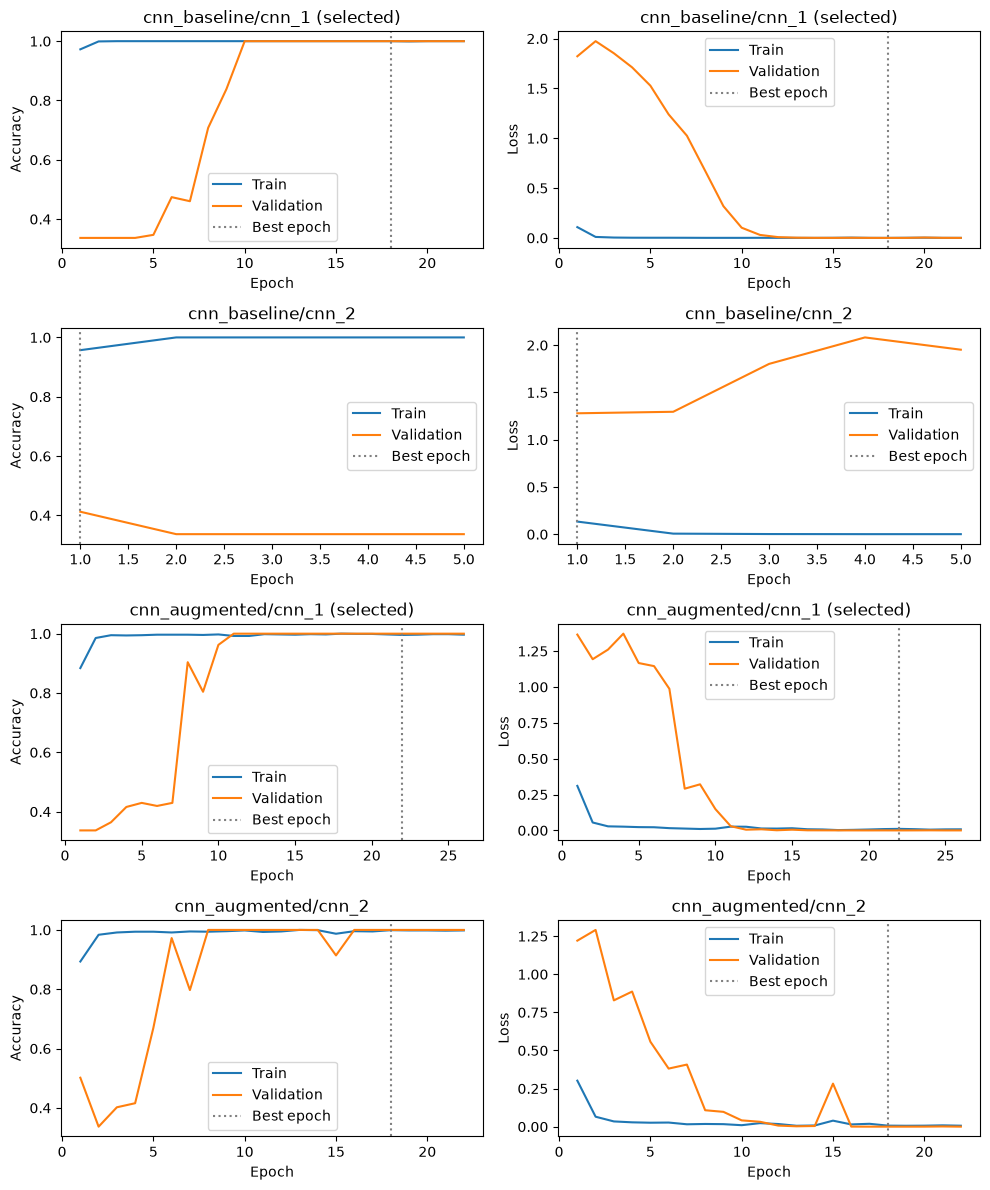

In [10]:
for scenario, augment in scenarios.items():
    name = f'cnn_{scenario}'
    models[name] = fit_candidates(build_cnn, cnn_specs, name, augment)
    evaluate(models[name], name, ds_test, test, 'test')

tuning_results('cnn')

**Hasil tuning dan testing CNN.** CNN-1 terpilih sebagai model terbaik pada kedua skenario. Pada baseline, nilai validation loss terendah sebesar 0,000244 dicapai pada epoch ke-18 dari total 22 epoch. Sementara itu, pada skenario augmented, nilai terendah sebesar $4.59358\times10^-5$ diperoleh pada epoch ke-22 dari total 26 epoch. Kedua model menghasilkan akurasi validasi sebesar 100%. CNN-2 tidak terpilih karena menghasilkan validation loss yang lebih tinggi pada masing-masing skenario. Pada pengujian testing, kedua model CNN berhasil mengklasifikasikan seluruh 485 gambar dengan benar, sehingga memperoleh akurasi dan macro F1 masing-masing sebesar 1 (100%).

## 3.3 Prediksi Gambar Baru dengan CNN

CNN diuji pada 60 gambar eksternal yang sama dengan ANN. Prediksi menggunakan $\widehat y_i=\arg\max_k\widehat p_{ik}$. Perbandingan didasarkan pada akurasi, macro F1, dan confusion matrix.

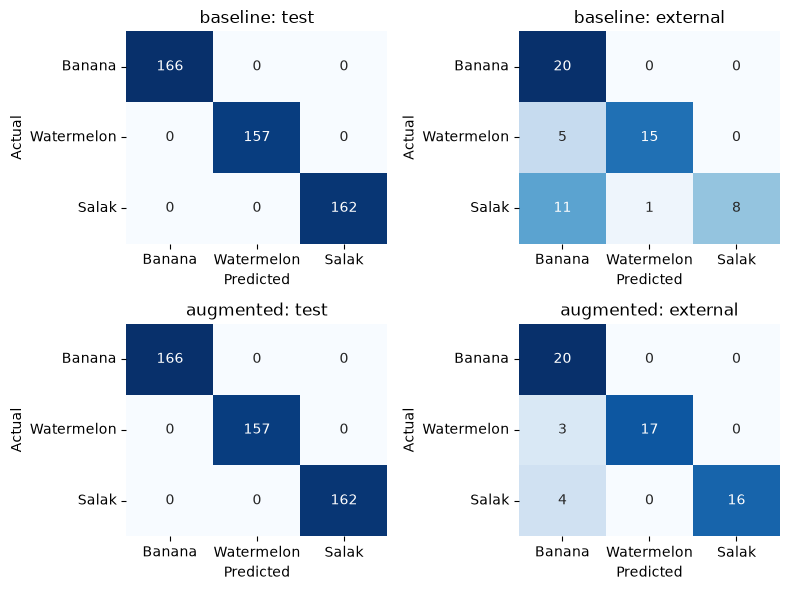

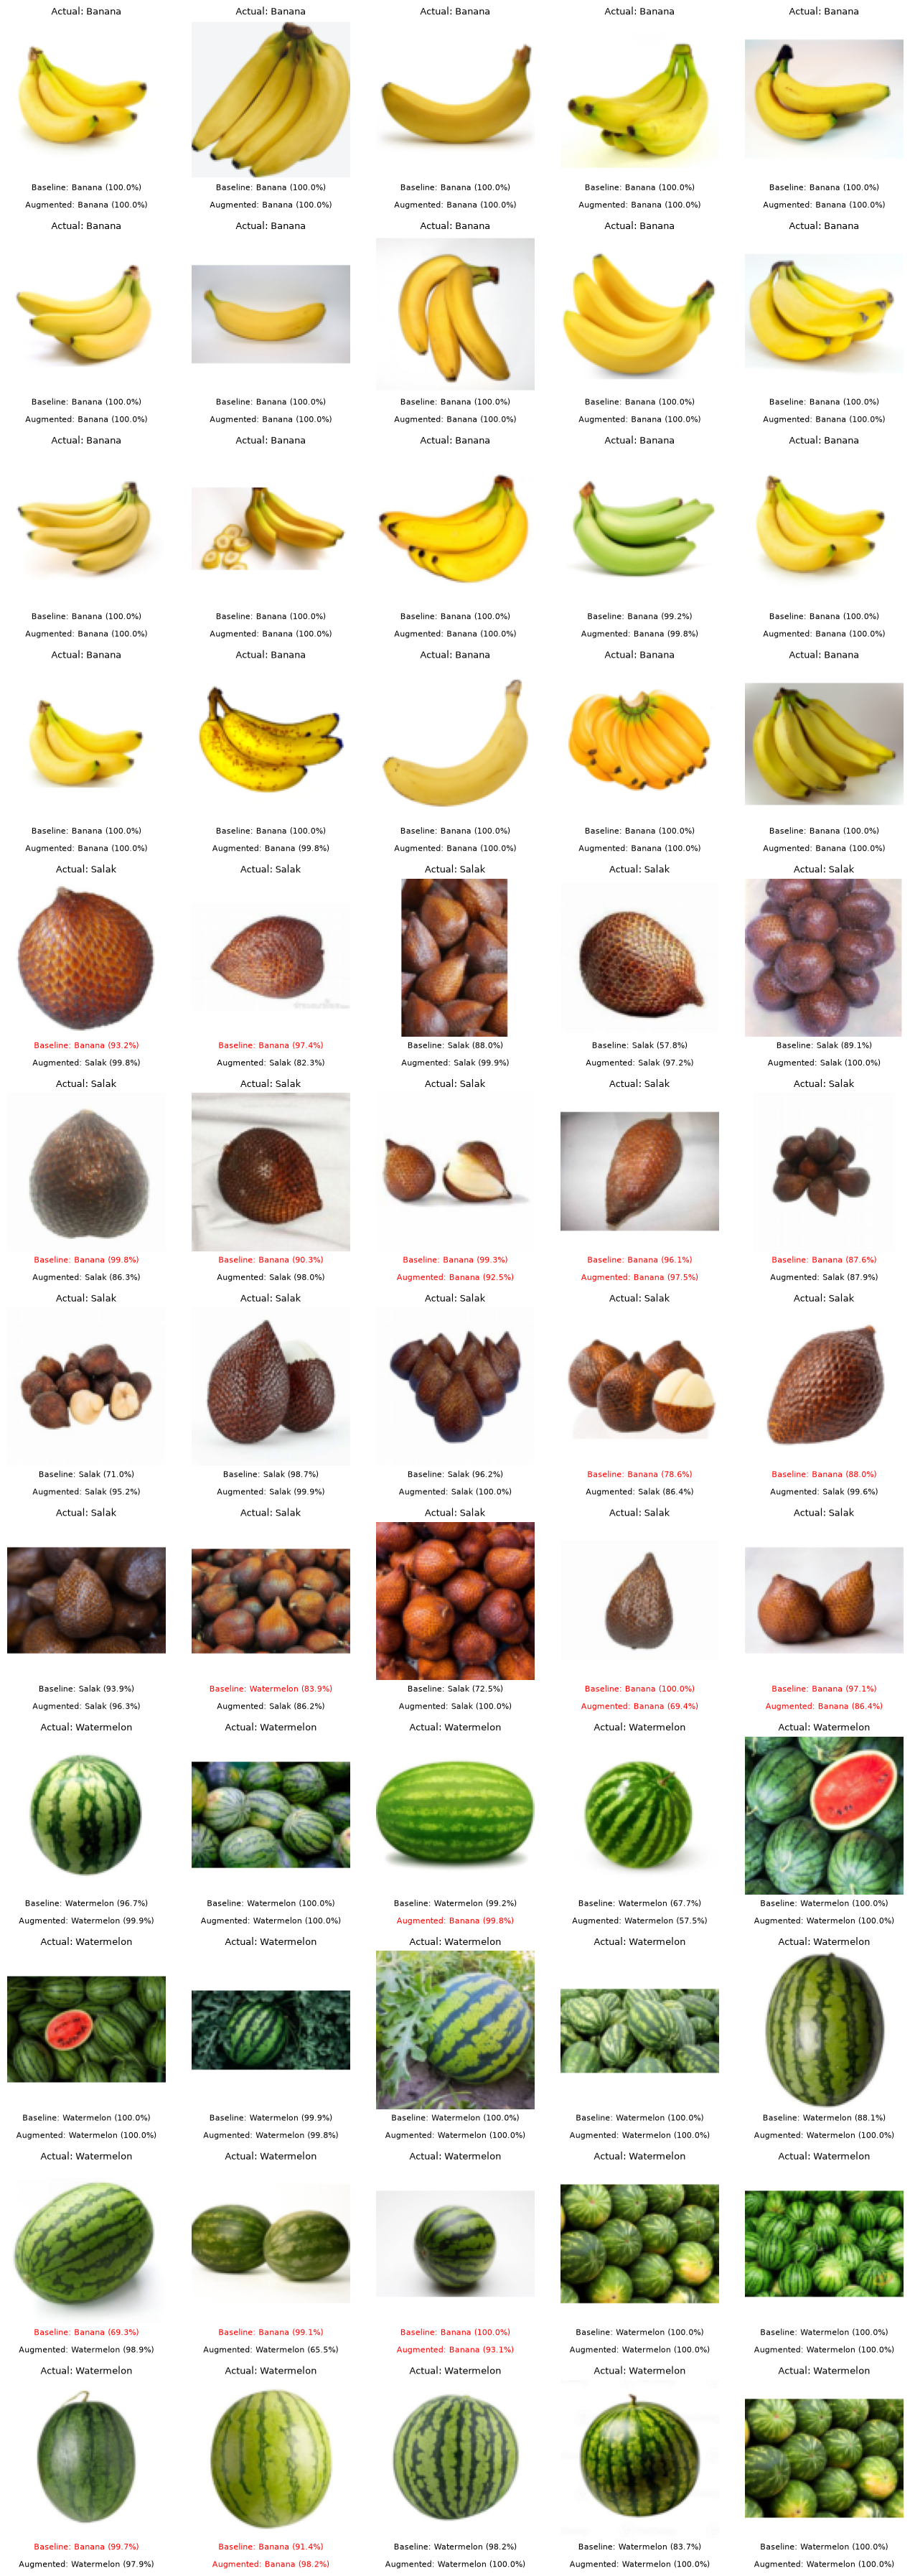

,model,path,actual,predicted,p_max
0,cnn_baseline,New-Fruits/Banana/Image_1.jpg,Banana,Banana,1.0000
1,cnn_baseline,New-Fruits/Salak/Image_1.jpg,Salak,Banana,0.9319
2,cnn_baseline,New-Fruits/Watermelon/Image_1.jpg,Watermelon,Watermelon,0.9669
3,cnn_augmented,New-Fruits/Banana/Image_1.jpg,Banana,Banana,1.0000
4,cnn_augmented,New-Fruits/Salak/Image_1.jpg,Salak,Salak,0.9976
5,cnn_augmented,New-Fruits/Watermelon/Image_1.jpg,Watermelon,Watermelon,0.9992


,accuracy,macro_f1,n_error
cnn_baseline,0.7167,0.7063,17.0
cnn_augmented,0.8833,0.8863,7.0


In [11]:
external_results('cnn')

**Hasil eksternal CNN.** Model baseline memperoleh 43 prediksi benar dari 60 gambar dengan akurasi 71,67%, sedangkan model augmented menghasilkan 53 prediksi benar dengan akurasi 88,33%. Nilai macro F1 juga meningkat dari 0,7063 menjadi 0,8863.

## 3.4 Perbandingan Akurasi CNN dan ANN

Selisih akurasi dihitung dalam poin persentase.

$$\Delta=100(\mathrm{Acc}_{\rm CNN}-\mathrm{Acc}_{\rm ANN}).$$

CNN mengekstraksi fitur spasial melalui penggunaan filter dengan bobot bersama (shared weights), sedangkan ANN memproses citra dalam bentuk vektor piksel. Perbandingan kinerja kedua model dilakukan berdasarkan hasil pengujian pada data testing dan eksternal.

In [12]:
rows = []
for name, res in tuning.items():
    best = res.iloc[0]
    a, b = metrics[name, 'test'], metrics[name, 'external']
    rows.append({'model': name, 'candidate': best['candidate'],
                 'test_accuracy': a['accuracy'], 'test_macro_f1': a['macro_f1'],
                 'test_error': a['n_error'], 'external_accuracy': b['accuracy'],
                 'external_macro_f1': b['macro_f1'], 'external_error': b['n_error'],
                 'parameters': int(best['parameters']), 'train_time_s': best['train_time_s'],
                 'tune_time_s': res['train_time_s'].sum()})
comparison = pd.DataFrame(rows).set_index('model')
for scenario in scenarios:
    a = comparison.loc[f'ann_{scenario}']
    b = comparison.loc[f'cnn_{scenario}']
    delta = 100 * (b.test_accuracy - a.test_accuracy)
    print(f'{scenario}: CNN - ANN (test) = {delta:+.2f} pp; '
          f'(external) = {100*(b.external_accuracy-a.external_accuracy):+.2f} pp')
    if np.isclose(delta, 0):
        print('Akurasi testing setara.')
    elif delta > 0:
        print('CNN lebih akurat pada testing; hasil ini konsisten dengan pemanfaatan fitur lokal.')
    else:
        print('ANN lebih akurat pada testing; ekstraksi fitur CNN tidak menjamin akurasi lebih tinggi.')

baseline: CNN - ANN (test) = +0.00 pp; (external) = +11.67 pp
Akurasi testing setara.
augmented: CNN - ANN (test) = +1.24 pp; (external) = +1.67 pp
CNN lebih akurat pada testing; hasil ini konsisten dengan pemanfaatan fitur lokal.


**Perbandingan.** Pada skenario baseline, kedua metode memperoleh akurasi testing yang sama, yaitu 100%, sedangkan CNN menghasilkan akurasi eksternal 11,67 poin persentase lebih tinggi. Pada skenario augmented, CNN menunjukkan keunggulan sebesar 1,24 poin persentase pada testing dan 1,67 poin persentase pada pengujian eksternal. Hasil ini menunjukkan bahwa CNN mampu memanfaatkan informasi bentuk dan tekstur dalam gambar. Namun, perbedaan kinerja pada pengujian eksternal skenario augmented masih relatif kecil sehingga belum cukup untuk menyimpulkan keunggulan pada populasi yang lebih luas.

# 4. Kesimpulan dan Analisis Perbandingan

## 4.1 Perbandingan Kinerja Model

Kompleksitas model ditentukan berdasarkan jumlah parameter yang digunakan, termasuk parameter statistik bergerak pada Batch Normalization. Jumlah parameter pada lapisan dense dan konvolusi dihitung sebagai berikut.

$$q_{\rm dense}=(n_{\rm in}+1)n_{\rm out},\qquad q_{\rm conv}=(k_h k_w C_{\rm in}+1)C_{\rm out}.$$

Durasi training dihitung berdasarkan waktu yang dibutuhkan untuk melatih kandidat model terpilih, sedangkan waktu tuning merupakan akumulasi durasi pelatihan kedua kandidat dalam setiap skenario. Kemampuan generalisasi dievaluasi menggunakan akurasi eksternal, macro F1, serta perbedaan akurasi antara data testing dan eksternal.

In [13]:
comparison['gap_pp'] = 100 * (comparison['test_accuracy'] - comparison['external_accuracy'])
display(comparison[['candidate', 'test_accuracy', 'test_macro_f1', 'external_accuracy',
                    'external_macro_f1', 'parameters', 'train_time_s', 'tune_time_s', 'gap_pp']].round(4))
save_table(comparison, 'model_comparison', index=True)
save_table(pd.concat(tuning.values(), ignore_index=True), 'tuning')
save_table(pd.concat(reports, ignore_index=True), 'classification_report')
save_table(pd.concat(predictions, ignore_index=True), 'predictions')
pd.concat(histories, ignore_index=True).to_csv(log_dir / 'training_history.csv', index=False)

config = dict(seed=seed, classes=classes, class_map=class_map, image_size=image_size,
              batch_size=batch_size, max_epochs=max_epochs, patience=patience, lr=lr,
              dropout=dropout_rate, val_ratio=val_ratio, ann_specs=ann_specs,
              cnn_specs=cnn_specs, class_weight=class_weight, scenarios=scenarios,
              monitor='val_loss', additional_test_ratio=0.2, white_threshold=240, background_probability=0.5,
              background_range=[0.15, 0.95], rotation=0.15, zoom=0.15,
              translation=0.1, contrast=0.2, brightness=0.15)
(log_dir / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
pkgs = ['tensorflow', 'numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'pillow']
(log_dir / 'requirements.txt').write_text('\n'.join(f'{p}=={version(p)}' for p in pkgs)+'\n', encoding='utf-8')

for family in ['ann', 'cnn']:
    a = comparison.loc[f'{family}_baseline']
    b = comparison.loc[f'{family}_augmented']
    print(f'{family}: augmented - baseline (test) = {100*(b.test_accuracy-a.test_accuracy):+.2f} pp; '
          f'(external) = {100*(b.external_accuracy-a.external_accuracy):+.2f} pp')

,candidate,test_accuracy,test_macro_f1,external_accuracy,external_macro_f1,parameters,train_time_s,tune_time_s,gap_pp
model,,,,,,,,,
ann_baseline,ann_2,1.0000,1.0000,0.6000,0.5743,3849347,29.7718,43.6437,40.0000
ann_augmented,ann_2,0.9876,0.9878,0.8667,0.8704,3849347,19.1818,31.4305,12.0962
cnn_baseline,cnn_1,1.0000,1.0000,0.7167,0.7063,28643,88.5779,129.3087,28.3333
cnn_augmented,cnn_1,1.0000,1.0000,0.8833,0.8863,28643,119.7467,277.1574,11.6667


ann: augmented - baseline (test) = -1.24 pp; (external) = +26.67 pp
cnn: augmented - baseline (test) = +0.00 pp; (external) = +16.67 pp


**Analisis kinerja.** CNN dengan augmentasi memperoleh hasil terbaik pada pengujian eksternal, dengan akurasi 88,33% dan macro F1 sebesar 0,8863 serta selisih akurasi testing dan eksternal sebesar 11,67 poin persentase. Penerapan augmentasi meningkatkan akurasi eksternal ANN sebesar 26,67 poin persentase dan CNN sebesar 16,67 poin persentase, tanpa mengubah arsitektur model yang terpilih pada masing-masing metode.

ANN-2 memiliki 3.849.347 parameter, sedangkan CNN-1 hanya menggunakan 28.643 parameter, sehingga jumlah parameter ANN sekitar 134,39 kali lebih besar dibandingkan CNN. Dari segi waktu pelatihan, ANN dan CNN masing-masing membutuhkan 28,90 dan 82,86 detik pada skenario baseline, serta 17,61 dan 111,33 detik pada skenario augmented. Dengan demikian, CNN memiliki jumlah parameter yang jauh lebih sedikit, tetapi membutuhkan waktu pelatihan lebih lama dalam hal ini.

## 4.2 Kelebihan, Keterbatasan, dan Kesimpulan

ANN menggunakan arsitektur yang lebih sederhana dengan durasi pelatihan lebih singkat, tetapi proses flatten menyebabkan hubungan spasial antarpiksel tidak dipertahankan secara eksplisit. Sebaliknya, CNN mampu mengenali pola lokal melalui filter konvolusi dengan bobot yang digunakan secara bersama. Penggunaan GAP juga mengurangi jumlah parameter model, meskipun operasi konvolusi membutuhkan komputasi yang lebih besar dan berdampak pada waktu pelatihan.

Dataset Fruits-360 memiliki kondisi latar dan pencahayaan yang relatif seragam. Penggunaan latar sintetis dalam augmentasi dapat menambah keragaman data training, tetapi belum sepenuhnya mewakili variasi gambar nyata. Selain itu, pembagian data secara acak dalam folder Training memungkinkan gambar dari objek yang sama masuk ke kelompok training dan validation. Perbedaan distribusi $P_(X,Y)\neq P_(X,Y)$ turut membatasi kemampuan generalisasi model. Pemeriksaan duplikasi juga hanya didasarkan pada path file, bukan kesamaan isi gambar. Oleh karena itu, evaluasi menggunakan gambar eksternal dalam model perlu dipandang sebagai analisis eksploratif.

In [14]:
for scenario in scenarios:
    a = comparison.loc[f'ann_{scenario}']
    b = comparison.loc[f'cnn_{scenario}']
    d = 100 * (b.external_accuracy - a.external_accuracy)
    label = 'setara' if np.isclose(d, 0) else ('CNN unggul' if d > 0 else 'ANN unggul')
    print(f'{scenario}: akurasi eksternal {label} ({abs(d):.2f} pp).')
    print(f'Rasio parameter ANN/CNN = {a.parameters/b.parameters:.2f}; '
          f'rasio waktu training ANN/CNN = {a.train_time_s/b.train_time_s:.2f}.')

baseline: akurasi eksternal CNN unggul (11.67 pp).
Rasio parameter ANN/CNN = 134.39; rasio waktu training ANN/CNN = 0.34.
augmented: akurasi eksternal CNN unggul (1.67 pp).
Rasio parameter ANN/CNN = 134.39; rasio waktu training ANN/CNN = 0.16.


**Kesimpulan.** CBerdasarkan hasil pengujian, CNN augmented menunjukkan kinerja terbaik secara deskriptif dengan akurasi testing sebesar 100% dan akurasi eksternal 88,33%. Sementara itu, ANN augmented memperoleh akurasi masing-masing sebesar 98,76% dan 86,67%. CNN memiliki jumlah parameter lebih sedikit dan akurasi yang sedikit lebih tinggi pada data eksternal, tetapi membutuhkan waktu pelatihan lebih lama. Penerapan augmentasi juga meningkatkan kemampuan generalisasi kedua metode pada sampel eksternal yang diuji. Meskipun demikian, hasil penelitian ini terbatas pada tiga kelas buah dan data yang digunakan, sehingga diperlukan pengujian tambahan dengan data independen untuk mengevaluasi kemampuan generalisasi pada cakupan yang lebih luas.

Referensi: Mureșan, H., & Oltean, M. (2018). Fruit recognition from images using deep learning. *Acta Universitatis Sapientiae, Informatica, 10*(1), 26–42. https://doi.org/10.2478/ausi-2018-0002